# 1. Exploratory Data Analysis (EDA):
○ Load the dataset and display the first few rows.

○ Check for missing values and handle them appropriately.

○ Generate summary statistics for the numerical columns.

○ Visualize the distribution of units sold using a histogram.

○ Plot the trend of units sold over the years using a line chart.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# Load the dataset

In [2]:
df = pd.read_csv('/content/top 120 best-selling mobile phones.csv')

# 1. Display the first few rows

In [3]:
print("\n--- First Few Rows ---\n")
print(df.head())


--- First Few Rows ---

   Rank Manufacturer                Model  Form Factor  Smartphone?  Year  \
0     1        Nokia                 1100          Bar        False  2003   
1     2        Nokia                 1110          Bar        False  2005   
2     3        Apple    iPhone 6 & 6 Plus  Touchscreen         True  2014   
3     4        Nokia           105 Series          Bar        False  2013   
4     5        Apple  iPhone 6S & 6S Plus  Touchscreen         True  2015   

   Units Sold (million )  
0                  250.0  
1                  247.5  
2                  222.4  
3                  200.0  
4                  174.1  


# 2. Check for missing values

In [4]:
print("\n--- Missing Values Check ---\n")
print(df.isnull().sum())


--- Missing Values Check ---

Rank                     0
Manufacturer             0
Model                    0
Form Factor              0
Smartphone?              0
Year                     0
Units Sold (million )    0
dtype: int64



# Handle missing values (if any)

In [5]:
if df.isnull().values.any():
    print("Missing values found. Dropping rows with missing values...")
    df = df.dropna()
else:
    print("No missing values found.")

No missing values found.



# 3. Summary statistics for numerical columns

In [6]:
print("\n--- Summary Statistics ---\n")
print(df.describe())


--- Summary Statistics ---

             Rank         Year  Units Sold (million )
count  120.000000   120.000000             120.000000
mean    60.500000  2012.758333              48.050000
std     34.785054     6.590030              58.044835
min      1.000000  1996.000000               2.000000
25%     30.750000  2007.000000              10.000000
50%     60.500000  2013.000000              22.050000
75%     90.250000  2019.000000              60.000000
max    120.000000  2024.000000             250.000000


# 4. Visualize the distribution of units sold using a histogram

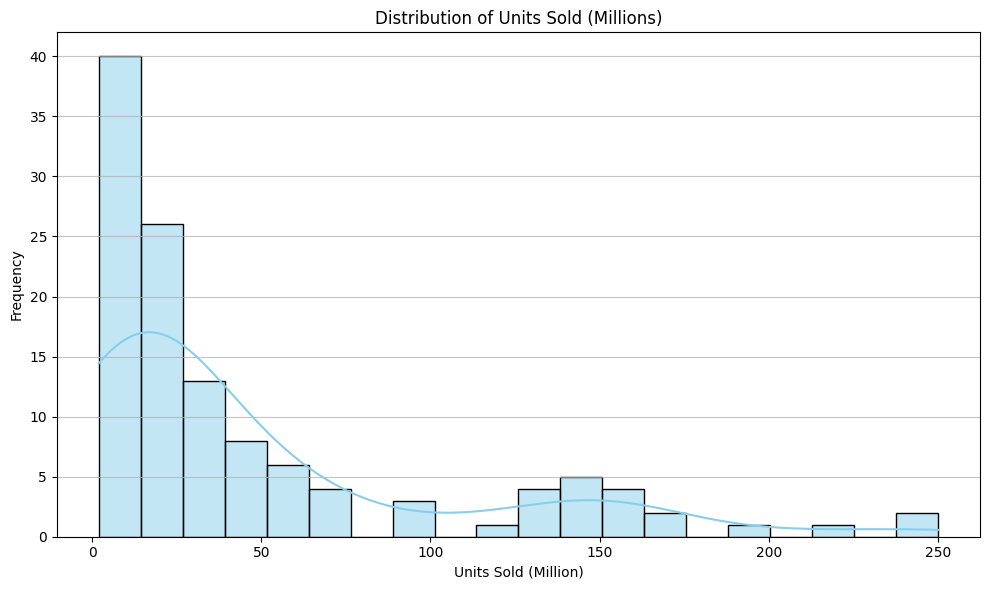

In [7]:
plt.figure(figsize=(10, 6))
sns.histplot(df['Units Sold (million )'], bins=20, kde=True, color='skyblue')
plt.title('Distribution of Units Sold (Millions)')
plt.xlabel('Units Sold (Million)')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.tight_layout()
plt.show()

# 5. Plot the trend of units sold over the years using a line chart
# First, group by Year and sum the units sold for that year

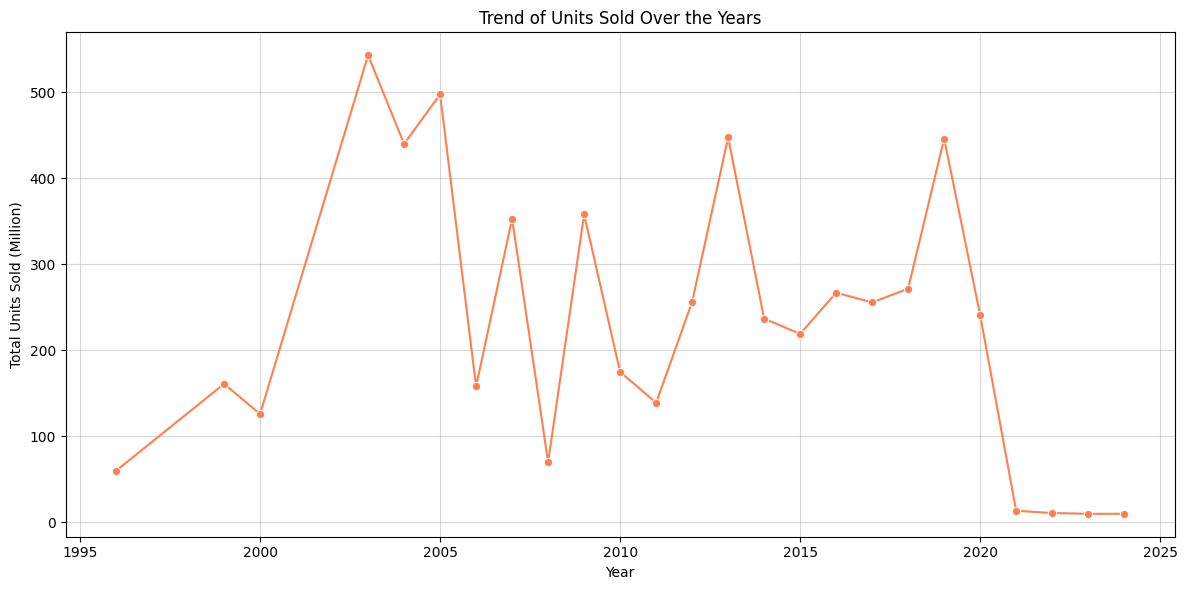

In [8]:
yearly_sales = df.groupby('Year')['Units Sold (million )'].sum().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(data=yearly_sales, x='Year', y='Units Sold (million )', marker='o', color='coral')
plt.title('Trend of Units Sold Over the Years')
plt.xlabel('Year')
plt.ylabel('Total Units Sold (Million)')
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()

# 2. Statistical Analysis:
○ Perform a t-test to determine if there is a significant difference in the
units sold between smartphones and non-smartphones.

○ Calculate the correlation matrix and visualize it using a heatmap.


Smartphones (Mean): 37.01M | Non-Smartphones (Mean): 74.87M
Welch's t-test: t = -2.9613, p-value = 0.0047


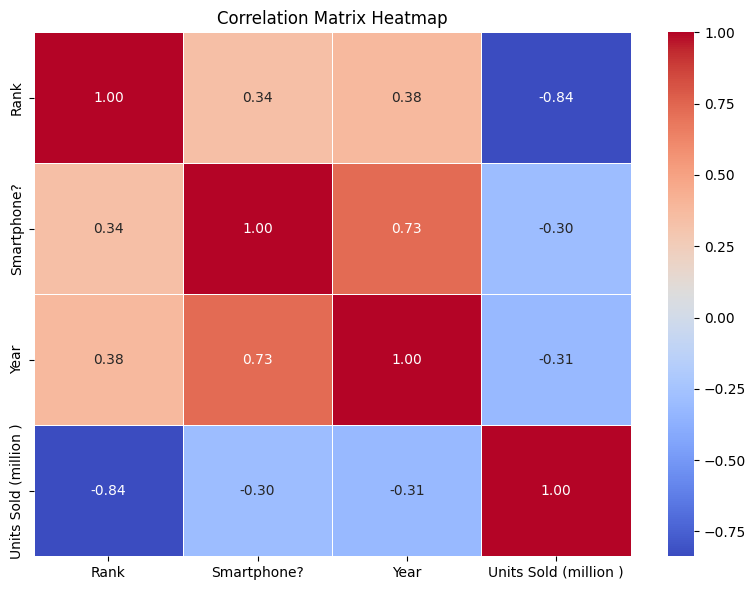

In [9]:

from scipy import stats


# 2. Independent Two-Sample T-Test
smartphones = df[df['Smartphone?'] == True]['Units Sold (million )']
non_smartphones = df[df['Smartphone?'] == False]['Units Sold (million )']

t_stat, p_val = stats.ttest_ind(smartphones, non_smartphones, equal_var=False)

print(f"Smartphones (Mean): {smartphones.mean():.2f}M | Non-Smartphones (Mean): {non_smartphones.mean():.2f}M")
print(f"Welch's t-test: t = {t_stat:.4f}, p-value = {p_val:.4f}")

# 3. Correlation Matrix & Heatmap
numeric_df = df.select_dtypes(include=['int64', 'float64', 'bool'])
corr_matrix = numeric_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix Heatmap')
plt.tight_layout()
plt.show()

# 3. Data Manipulation with Pandas:
○ Group the data by manufacturer and calculate the total units sold for
each.

○ Identify the top 5 manufacturers with the highest total units sold.

○ Create a pivot table showing the total units sold per year for each
manufacturer.


In [14]:
# Store the exact column name for easier reference
units_col = 'Units Sold (million )'

# Task 1: Group by manufacturer and calculate total units sold
grouped_sales = df.groupby('Manufacturer')[units_col].sum().reset_index()
grouped_sales = grouped_sales.sort_values(by=units_col, ascending=False)

print("--- Total Units Sold by Manufacturer ---")
print(grouped_sales.to_string(index=False))


# Task 2: Identify the top 5 manufacturers
top_5_manufacturers = grouped_sales.head(5)

print("\n--- Top 5 Manufacturers ---\n")
print(top_5_manufacturers.to_string(index=False))


# Task 3: Create a pivot table for units sold per year by each manufacturer
pivot_table = pd.pivot_table(
    df,
    values=units_col,
    index='Manufacturer',
    columns='Year',
    aggfunc='sum',
    fill_value=0
)

print("\n--- Pivot Table: Units Sold Per Year by Manufacturer ---\n")
print(pivot_table)

--- Total Units Sold by Manufacturer ---
            Manufacturer  Units Sold (million )
                   Nokia                 2374.5
                   Apple                 1669.3
                 Samsung                  994.5
                Motorola                  323.0
                  Huawei                  113.8
                  Xiaomi                   99.1
                      LG                   92.0
           Sony Ericsson                   45.0
                    Oppo                   16.7
                     HTC                   16.0
Research in Motion (RIM)                   15.0
                    LeTV                    3.0
                  Google                    2.1
                    Palm                    2.0

--- Top 5 Manufacturers ---

Manufacturer  Units Sold (million )
       Nokia                 2374.5
       Apple                 1669.3
     Samsung                  994.5
    Motorola                  323.0
      Huawei                 

# 4. Data Visualization with Matplotlib and Seaborn:
○ Create a bar chart showing the top 10 best-selling mobile phone
models.

○ Use a box plot to compare the units sold for smartphones vs.
non-smartphones.


/tmp/ipykernel_857/4211659765.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_10, x=col_name, y='Full Model', palette='viridis')


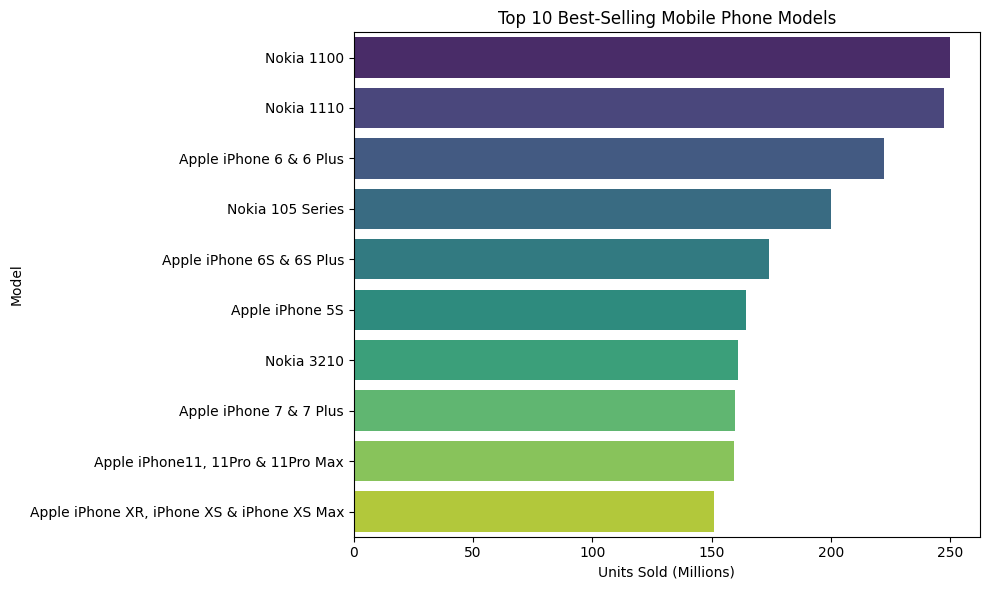

/tmp/ipykernel_857/4211659765.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Smartphone?', y=col_name, palette='Set2')


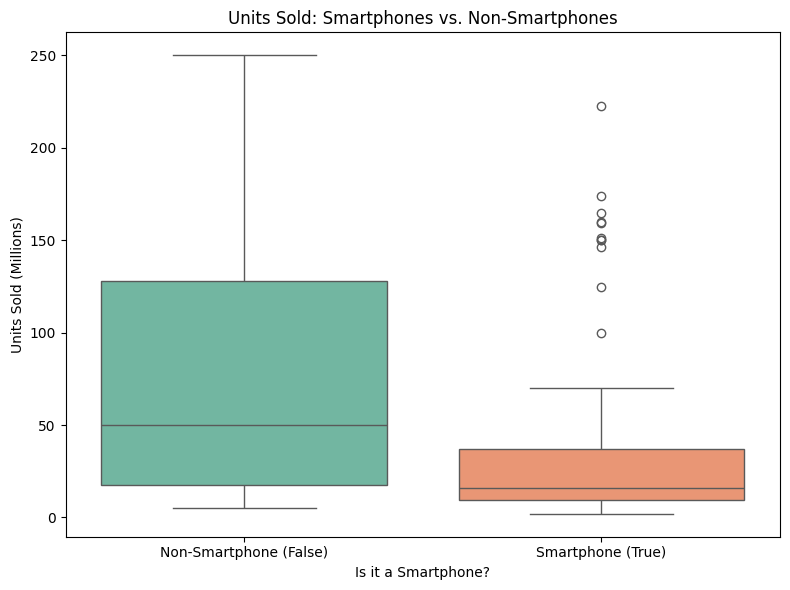

Images generated successfully.


In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


col_name = 'Units Sold (million )'

# Prepare data for Bar Chart (Top 10 models)
# Combine Manufacturer and Model for clearer labels
df['Full Model'] = df['Manufacturer'] + " " + df['Model']
top_10 = df.nlargest(10, col_name)

# 1. Bar Chart
plt.figure(figsize=(10, 6))
sns.barplot(data=top_10, x=col_name, y='Full Model', palette='viridis')
plt.title('Top 10 Best-Selling Mobile Phone Models')
plt.xlabel('Units Sold (Millions)')
plt.ylabel('Model')
plt.tight_layout()
plt.show()

# 2. Box Plot
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='Smartphone?', y=col_name, palette='Set2')
plt.title('Units Sold: Smartphones vs. Non-Smartphones')
plt.xlabel('Is it a Smartphone?')
plt.ylabel('Units Sold (Millions)')
plt.xticks([0, 1], ['Non-Smartphone (False)', 'Smartphone (True)'])
plt.tight_layout()
plt.show()

print("Images generated successfully.")

# 5. Machine Learning:
○ Build a simple linear regression model to predict units sold based on
the year.

○ Evaluate the model's performance using R-squared and mean
squared error.


In [17]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

col_name = 'Units Sold (million )'

# Define features (X) and target (y)
X = df[['Year']]  # Scikit-learn expects 2D array for features
y = df[col_name]

# Split the data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared (R2): {r2:.4f}")
print(f"Model Coefficient (Slope): {model.coef_[0]:.2f}")
print(f"Model Intercept: {model.intercept_:.2f}")

Mean Squared Error (MSE): 3460.24
R-squared (R2): 0.1617
Model Coefficient (Slope): -2.20
Model Intercept: 4482.03
